# Task 2.4: a better readout

**In plain words.** A readout has two ways to fail. The signal can be too small to tell the two states apart (misread), or the readout drive itself can kick the qubit into the other valley (bit flip). Both get worse together: a stronger drive gives more signal but also more flips, and both grow as $\epsilon_Z^2$, so turning up the drive does not help. The lever left is the drive's **shape in time**. We also check that the photon-pairing term itself survives in the real circuit.

**Prediction before simulating.** Task 2.3 showed the buffer rings at 3.2 MHz. A drive that oscillates at that frequency should pump the ringing up and get more signal out of the same peak drive, the way pushing a swing in time does. In the full circuit, the strong pump should shift the mode frequencies (Stark shift) and detune the pairing, so the pump frequency probably needs correcting.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F          # loads saved results/s2/*.json, draws the figures
from research.s2.notebook_figs import load, nominal, largest
import io
from contextlib import redirect_stdout
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))

In [2]:
with redirect_stdout(io.StringIO()):
    F.better_readout()

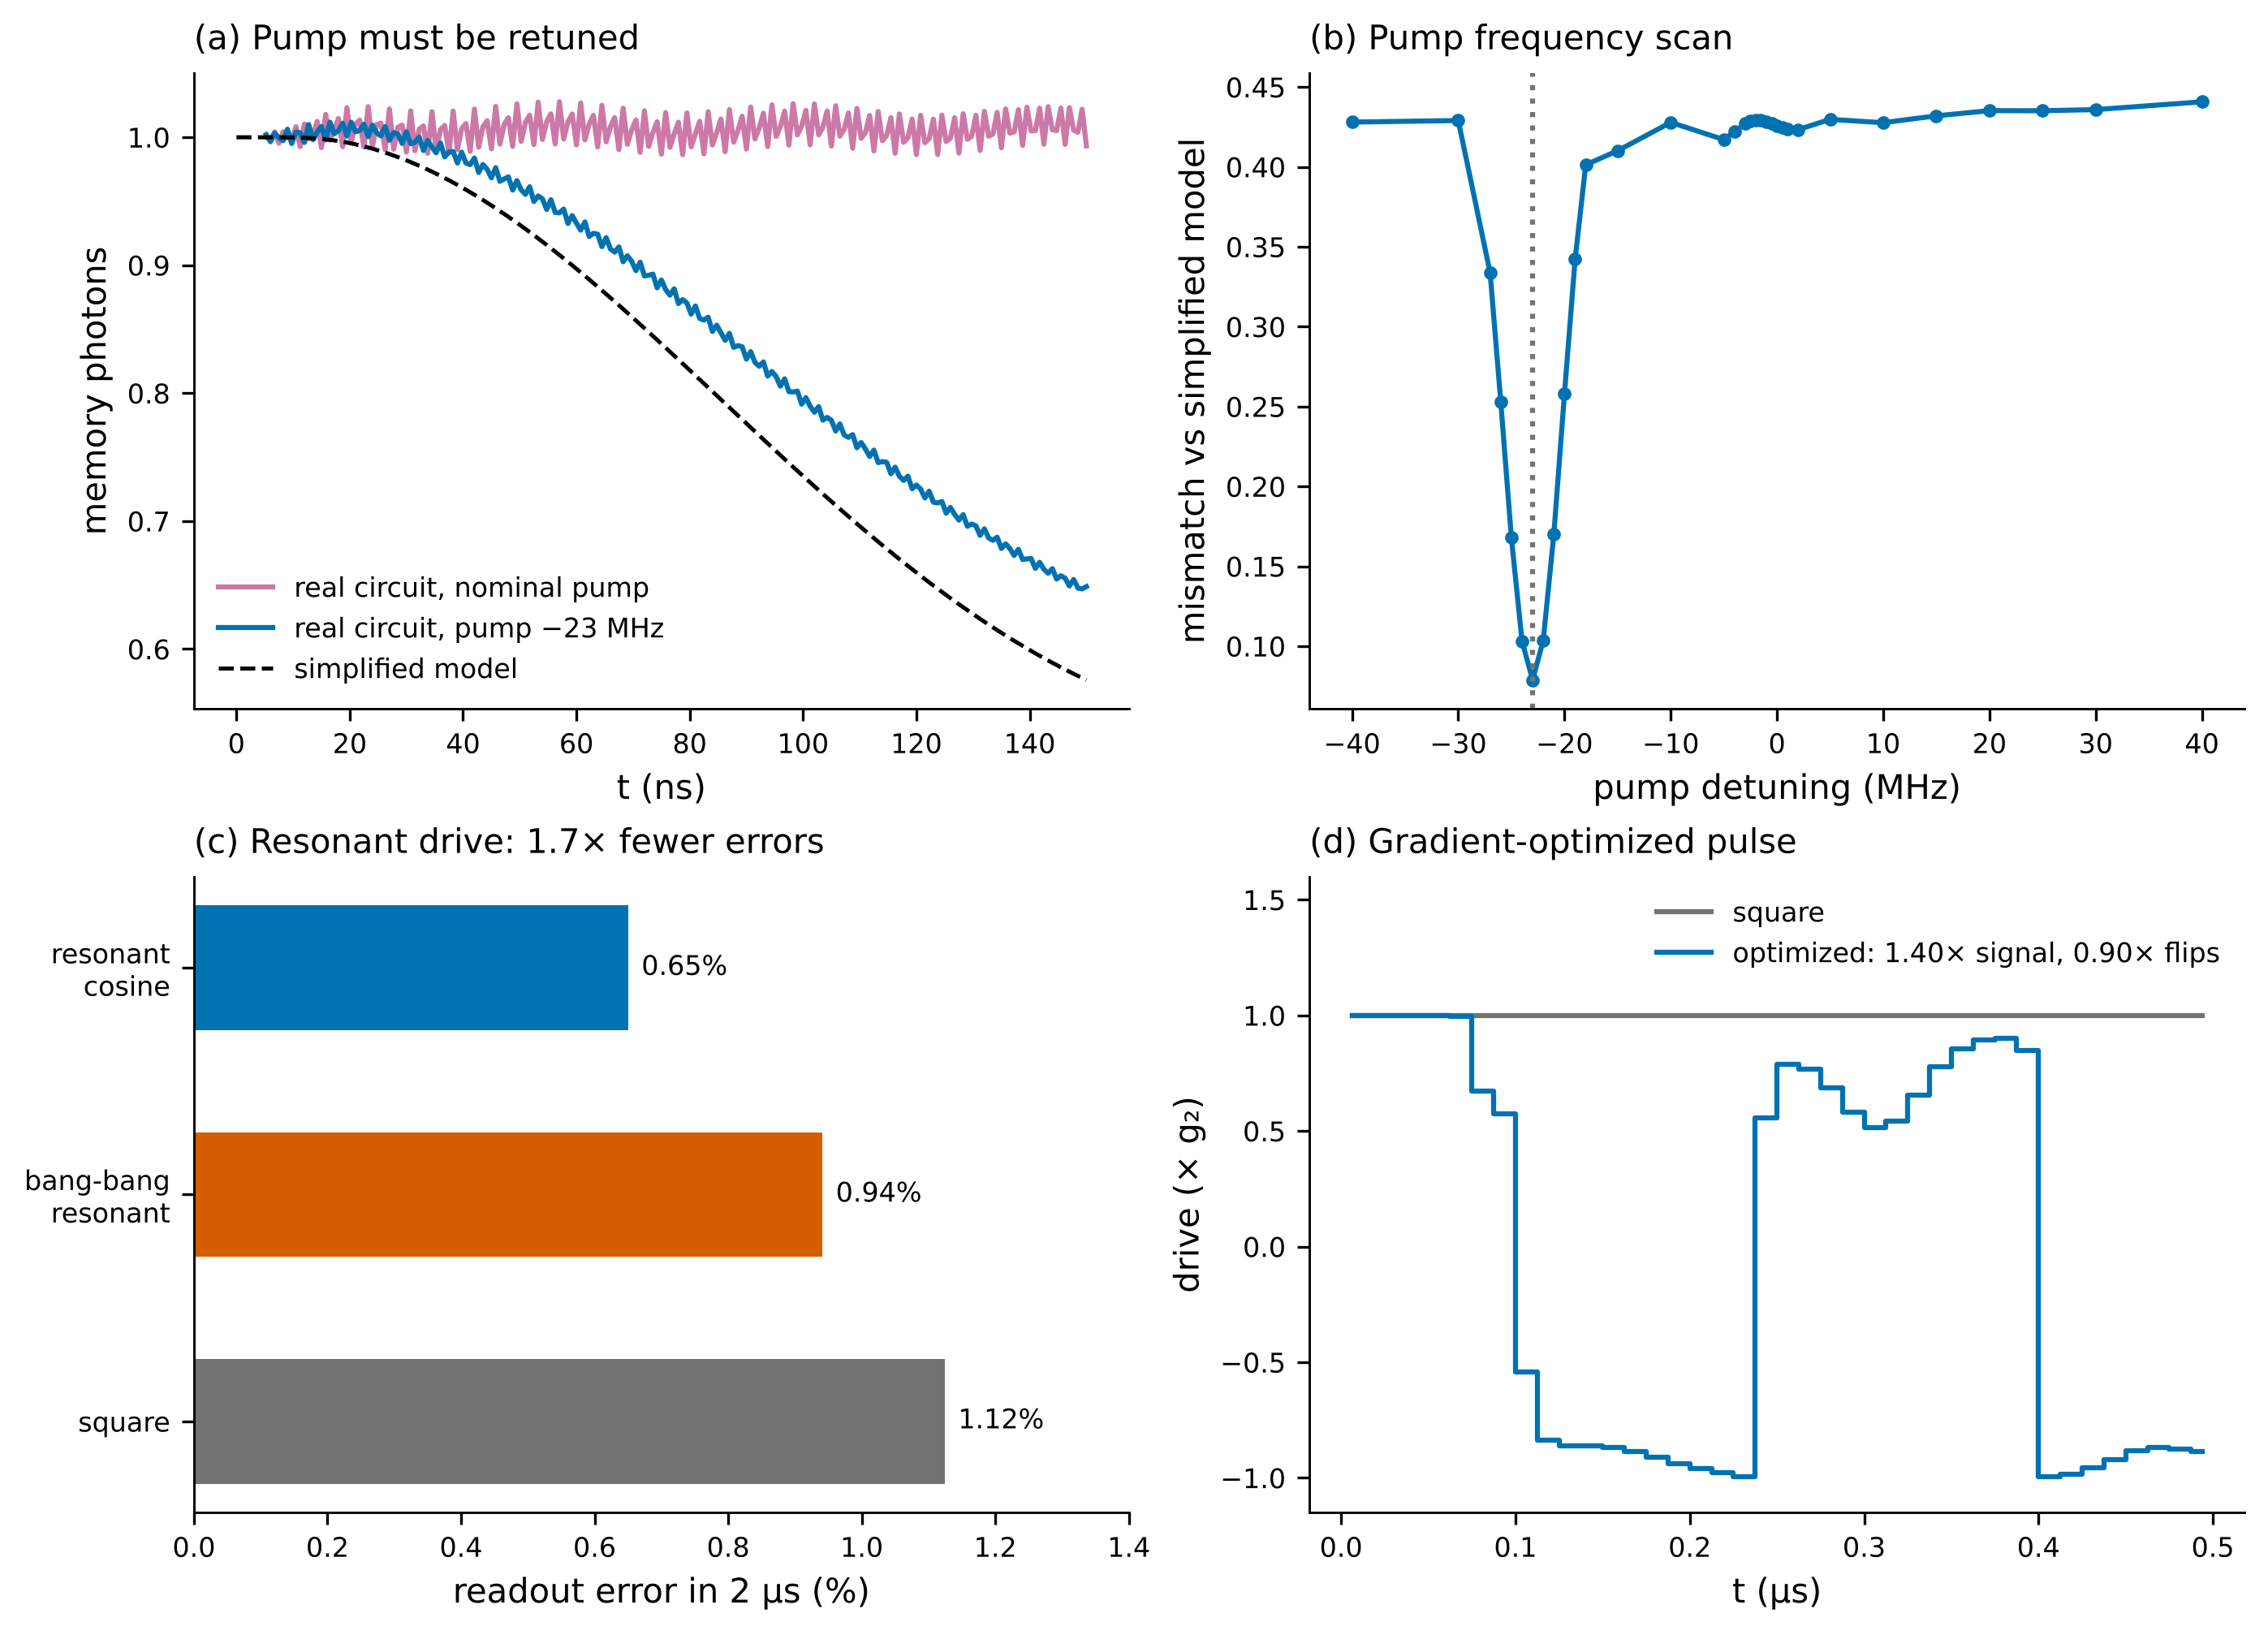

In [3]:
show('task_2_4_better_readout')

**Circuit check and readout pulse comparison.** (a) Memory photon number in the full circuit (no rotating-wave approximation), starting from one photon, 6 ns moving average to hide the fast pump ripple. Black dashed: the simplified pairing model $g_2(a^2b^\dagger + \mathrm{h.c.})$, which converts photon pairs into the buffer. Pink: the real circuit with the pump at its nominal frequency $2\omega_a - \omega_b$; pairing does not happen. Blue: pump moved by $-23$ MHz; the circuit now follows the simplified model. (b) Time-averaged mismatch between circuit and simplified model against pump detuning; the dip at $-23$ MHz (dotted) is the corrected pump frequency. Both panels use $14\times6$ and $10\times4$ levels; the effect is the same at $12\times5$. (c) Total readout error after 2 µs at $\alpha = 2.1$, i.e. misread probability $\tfrac12\mathrm{erfc}(\sqrt{\mathrm{SNR}/2})$ plus bit flip probability, for the best peak drive of each pulse shape. The resonant cosine is 1.7× better than a square pulse. (d) Pulse found by gradient descent through the simulator (blue, 40 time bins, 0.5 µs window, peak $1\,g_2$, started from the bang-bang resonant pulse) against the square pulse (grey). It keeps the sign changes at the ringing frequency and reshapes the amplitude, giving 40% more signal with 10% fewer flips.

In [4]:
from math import erfc, sqrt
ps = load('pulse_a2.10_30x8_T2_peak.json')[0]
err = lambda r: 0.5 * erfc(sqrt(r['snr'] / 2)) + r['p_flip']        # misread + flipped by the readout
names = {'square': 'square', 'bang': 'bang-bang resonant', 'res': 'resonant cosine'}
pd.DataFrame([{'pulse': names[f], 'best peak (× g₂)': r['level'], 'signal (SNR)': round(r['snr'], 1),
               'bit flip prob.': f"{r['p_flip']:.1e}", 'readout error': f"{100 * err(r):.2f}%"}
              for f in names for r in [min((r for r in ps['rows'] if r['family'] == f), key=err)]])

,pulse,best peak (× g₂),signal (SNR),bit flip prob.,readout error
0,square,1.00,7.5,8.1e-03,1.12%
1,bang-bang resonant,0.75,12.8,9.2e-03,0.94%
2,resonant cosine,0.75,8.2,4.4e-03,0.65%


**Result.**
- **The pump must be retuned by −23 MHz** in the real circuit, or the photon pairing that makes the cat qubit work switches off.
- **Driving at the ringing frequency cuts the readout error 1.7×** (1.12% → 0.65% in 2 µs).
- **A gradient-optimized pulse carries 1.3–1.7× more signal per bit flip** than a square pulse, in every one of the 9 converged settings below.

## Numerical diagnostics

Every optimizer run at a converged truncation (buffer ≥ 8 levels, run completed). The ratio columns compare the optimized pulse with a square pulse of the same peak and window.

In [5]:
opt = [d for d in load('opt_*.json') if not d.get('partial') and d['nb'] >= 8]
pd.DataFrame([{'α': d['alpha'], 'window (µs)': d['T'], 'peak (× g₂)': d['peak'], 'levels': f"{d['na']}×{d['nb']}",
               'signal vs square': round(d['best']['snr'] / d['square']['snr'], 2),
               'flips vs square': round(d['best']['p_flip'] / d['square']['p_flip'], 2),
               'signal per flip vs square': round(d['best']['ratio_vs_square'], 2)}
              for d in sorted(opt, key=lambda d: (d['alpha'], d['T'], d['peak']))])

,α,window (µs),peak (× g₂),levels,signal vs square,flips vs square,signal per flip vs square
0,1.4,0.5,0.5,22×8,0.89,0.58,1.55
1,1.4,0.5,1.0,22×8,0.94,0.57,1.66
2,1.4,1.0,0.5,22×8,1.13,0.71,1.59
3,1.8,0.5,0.5,26×8,1.27,0.93,1.36
4,1.8,0.5,1.0,26×8,1.13,0.66,1.71
5,1.8,1.0,0.5,26×8,1.88,1.42,1.32
6,2.1,0.5,0.5,30×8,1.51,1.20,1.26
7,2.1,0.5,1.0,30×8,1.40,0.90,1.56
8,2.1,1.0,0.5,30×8,1.71,1.31,1.30
